In [1]:
import numpy as np
import pandas as pd
import  matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
df = pd.read_csv(r"F:\enviroment\Student_Perfomance\StudentsPerformance.csv")
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
df.columns.to_list()

['gender',
 'race/ethnicity',
 'parental level of education',
 'lunch',
 'test preparation course',
 'math score',
 'reading score',
 'writing score']

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [5]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [6]:
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ', '_')
df = df.rename(columns={'race/ethnicity': 'ethnicity'})

### **Basic EDA**

In [7]:
px.pie(
    df,
    'gender',
    width=400, 
    height=300
)

In [8]:
px.pie(
    df,
    'ethnicity',
    width=400, 
    height=300
)

In [9]:
px.pie(
    df,
    'parental_level_of_education',
    width=500, 
    height=400
)

In [10]:
px.pie(
    df,
    'lunch',
    width=500, 
    height=400
)

In [11]:
px.pie(
    df,
    'test_preparation_course',
    width=500, 
    height=400
)

In [12]:
df['math_score'].describe()

count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math_score, dtype: float64

<Axes: xlabel='math_score', ylabel='Density'>

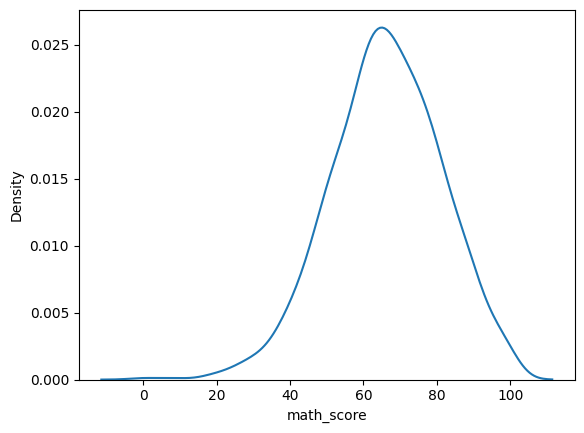

In [14]:
sns.kdeplot(
    data=df,
    x='math_score'
)

In [15]:
df['math_score'].skew()

np.float64(-0.27893514909431694)

- this clas hava a good student in maths subject, this data has a left skewed, most studnet have a good mark.
- but have a min mark is 0 this means some also weak student in class.

---

In [16]:
df['reading_score'].describe()

count    1000.000000
mean       69.169000
std        14.600192
min        17.000000
25%        59.000000
50%        70.000000
75%        79.000000
max       100.000000
Name: reading_score, dtype: float64

<Axes: xlabel='reading_score', ylabel='Density'>

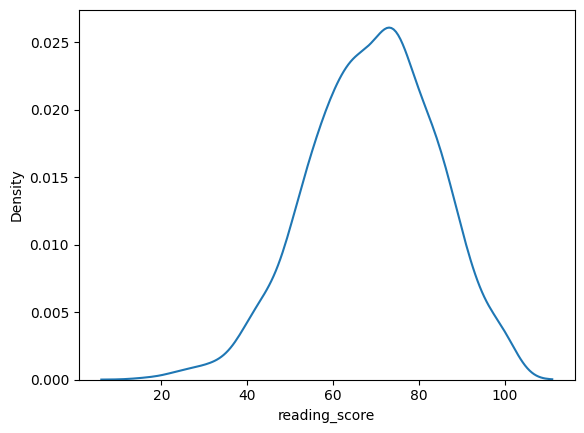

In [17]:
sns.kdeplot(
    data=df,
    x='reading_score'
)

In [18]:
df['reading_score'].skew()

np.float64(-0.25910451810923063)

- also good student in reading subject.
- this data also left skewed and none of the student have a marks means this subject is easy or we have a good student in class

In [19]:
df['writing_score'].describe()

count    1000.000000
mean       68.054000
std        15.195657
min        10.000000
25%        57.750000
50%        69.000000
75%        79.000000
max       100.000000
Name: writing_score, dtype: float64

<Axes: xlabel='writing_score', ylabel='Density'>

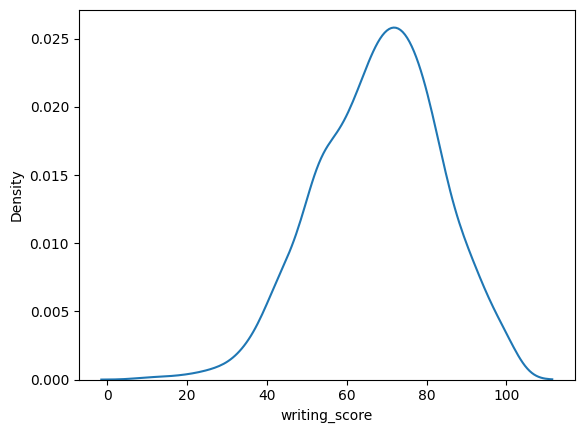

In [20]:
sns.kdeplot(
    data=df,
    x='writing_score'
)

In [21]:
df['writing_score'].skew()

np.float64(-0.28944397150761897)

- also good student in writing subject.
- this data also left skewed and none of the student have a 0 marks means this subject is easy or we have a good student in class

---

### **Feature Eng**

In [22]:
df['percentage'] = ((df['math_score'] + df['reading_score'] + df['writing_score']) / 300) * 100

<Axes: xlabel='percentage', ylabel='Density'>

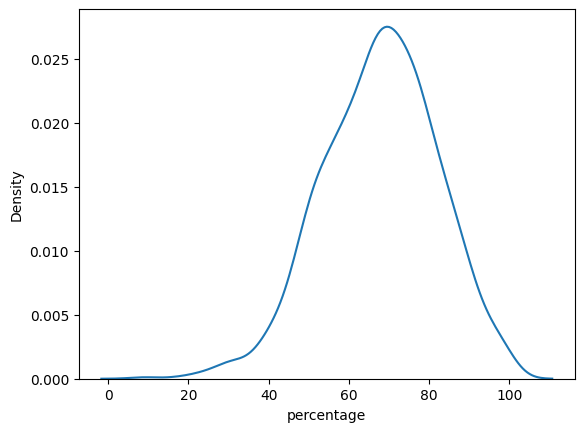

In [23]:
sns.kdeplot(
    data=df,
    x='percentage'
)

In [24]:
conditions = [
    df['percentage'] >= 90,
    df['percentage'] >= 80,
    df['percentage'] >= 70,
    df['percentage'] >= 60,
    df['percentage'] >= 50,
    df['percentage'] >= 33,
    df['percentage'] < 33
]

grades = ['A+', 'A', 'B', 'C', 'D', 'E', 'F']

df['grade'] = np.select(conditions, grades, default='Fail')

In [25]:
px.pie(
    df,
    'grade',
    width=500, 
    height=400
)

In [26]:
conditions = [
    df['percentage'] < 33,
    df['percentage'] < 50,
    df['percentage'] < 70,
    df['percentage'] < 85,
    df['percentage'] <= 100
]

categories = ['Fail', 'Poor', 'Average', 'Good', 'Excellent']

df['performance'] = np.select(conditions, categories, default='Unknown')

In [27]:
px.pie(
    df,
    'performance',
    width=500, 
    height=400
)

## **Analysis**

### Gender

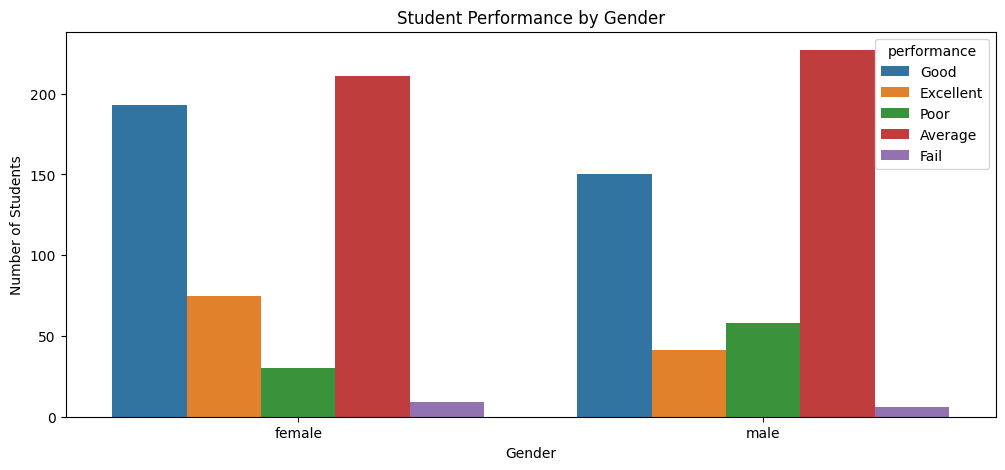

In [28]:
plt.figure(figsize=(12, 5))
sns.countplot(
    data=df,
    x='gender',
    hue='performance'
)

plt.title('Student Performance by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Students')
plt.show()

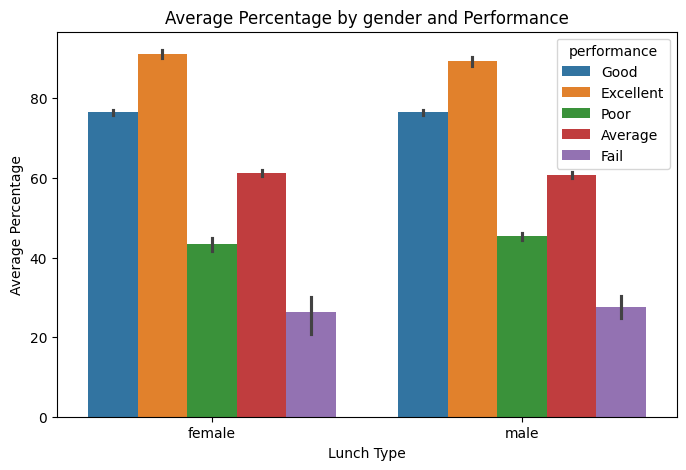

In [29]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='gender',
    y='percentage',
    hue='performance'
)

plt.title('Average Percentage by gender and Performance')
plt.xlabel('Lunch Type')
plt.ylabel('Average Percentage')
plt.show()

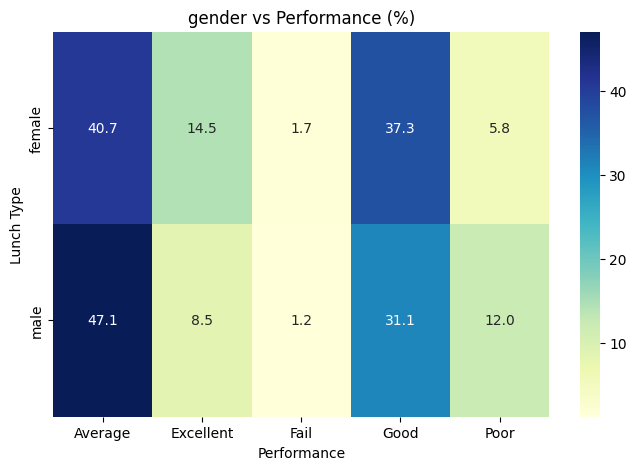

In [30]:
ct = pd.crosstab(
    df['gender'],
    df['performance'],
    normalize='index'
) * 100

plt.figure(figsize=(8, 5))

sns.heatmap(
    ct,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('gender vs Performance (%)')
plt.xlabel('Performance')
plt.ylabel('Lunch Type')
plt.show()

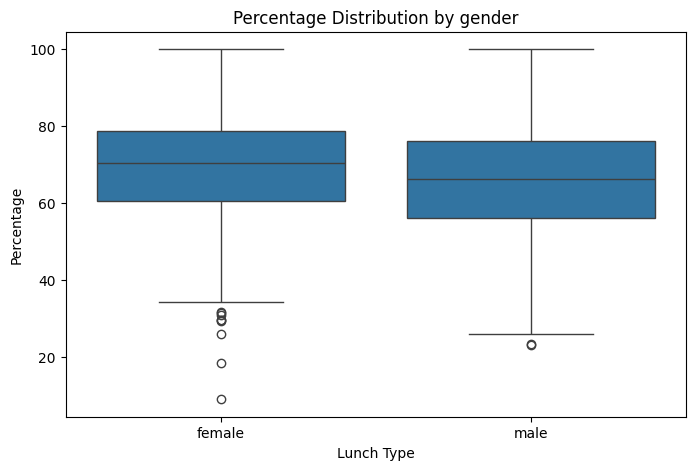

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='gender',
    y='percentage'
)

plt.title('Percentage Distribution by gender')
plt.xlabel('Lunch Type')
plt.ylabel('Percentage')
plt.show()

### Lunch

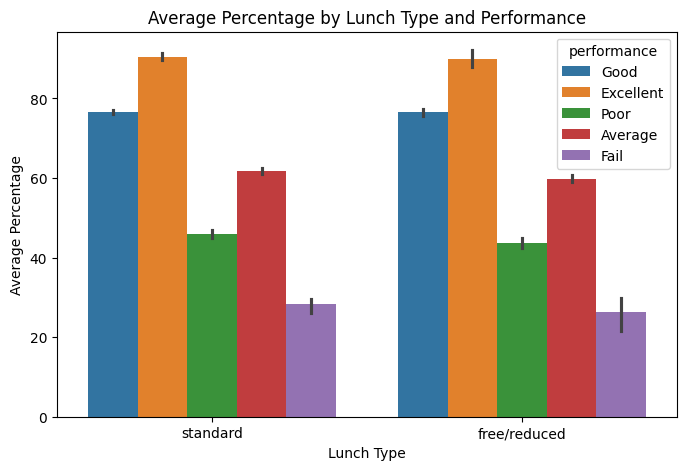

In [32]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='lunch',
    y='percentage',
    hue='performance'
)

plt.title('Average Percentage by Lunch Type and Performance')
plt.xlabel('Lunch Type')
plt.ylabel('Average Percentage')
plt.show()

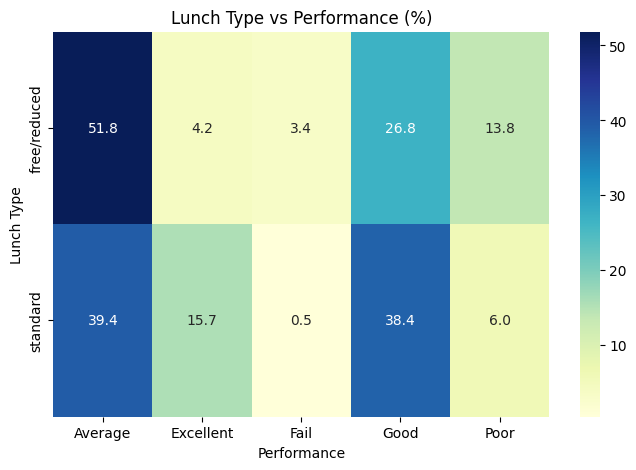

In [33]:
ct = pd.crosstab(
    df['lunch'],
    df['performance'],
    normalize='index'
) * 100

plt.figure(figsize=(8, 5))

sns.heatmap(
    ct,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('Lunch Type vs Performance (%)')
plt.xlabel('Performance')
plt.ylabel('Lunch Type')
plt.show()

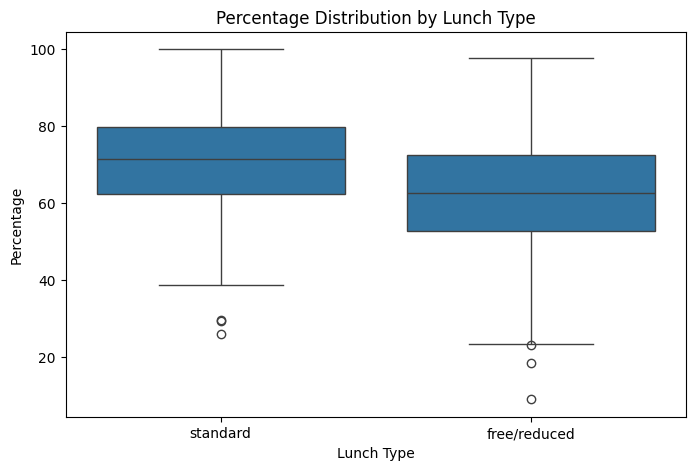

In [34]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='lunch',
    y='percentage'
)

plt.title('Percentage Distribution by Lunch Type')
plt.xlabel('Lunch Type')
plt.ylabel('Percentage')
plt.show()

### ethnicity

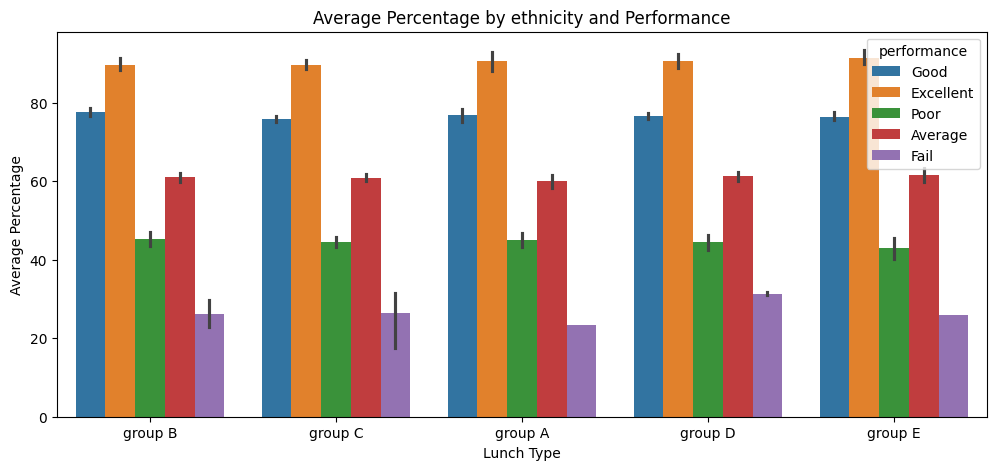

In [35]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=df,
    x='ethnicity',
    y='percentage',
    hue='performance'
)

plt.title('Average Percentage by ethnicity and Performance')
plt.xlabel('Lunch Type')
plt.ylabel('Average Percentage')
plt.show()

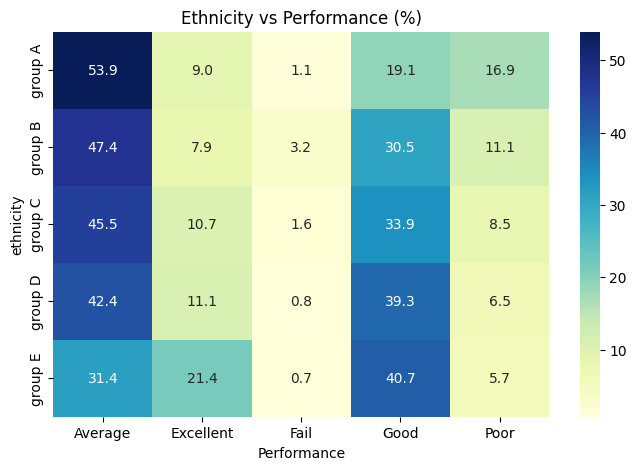

In [36]:
ct = pd.crosstab(
    df['ethnicity'],
    df['performance'],
    normalize='index'
) * 100

plt.figure(figsize=(8, 5))

sns.heatmap(
    ct,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('Ethnicity vs Performance (%)')
plt.xlabel('Performance')
plt.ylabel('ethnicity')
plt.show()

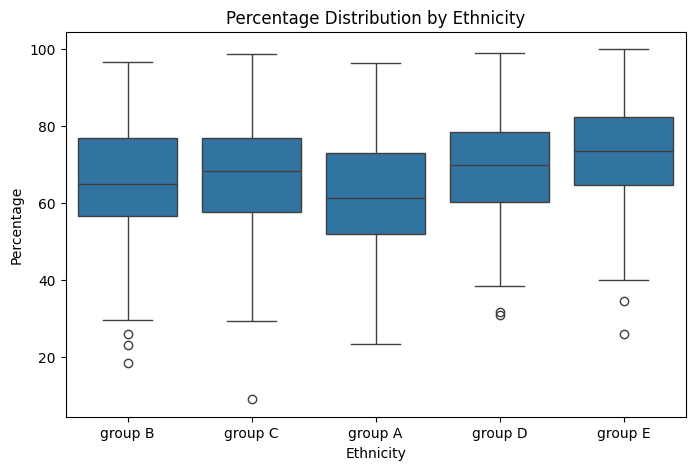

In [37]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='ethnicity',
    y='percentage'
)

plt.title('Percentage Distribution by Ethnicity')
plt.xlabel('Ethnicity')
plt.ylabel('Percentage')
plt.show()

### Parent Education

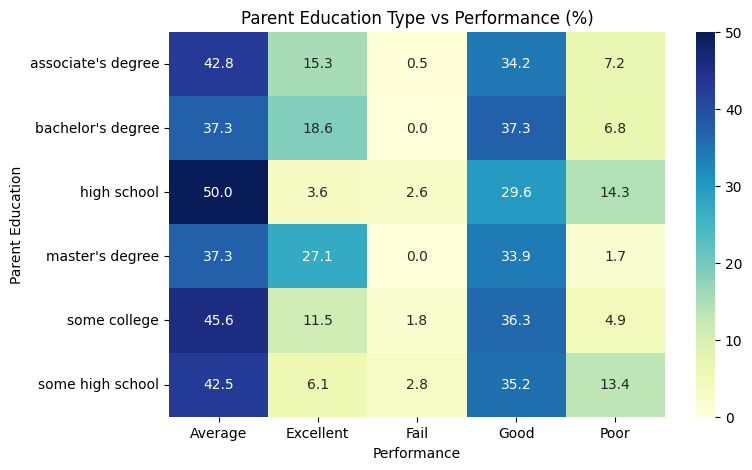

In [38]:
ct = pd.crosstab(
    df['parental_level_of_education'],
    df['performance'],
    normalize='index'
) * 100

plt.figure(figsize=(8, 5))

sns.heatmap(
    ct,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('Parent Education Type vs Performance (%)')
plt.xlabel('Performance')
plt.ylabel('Parent Education')
plt.show()

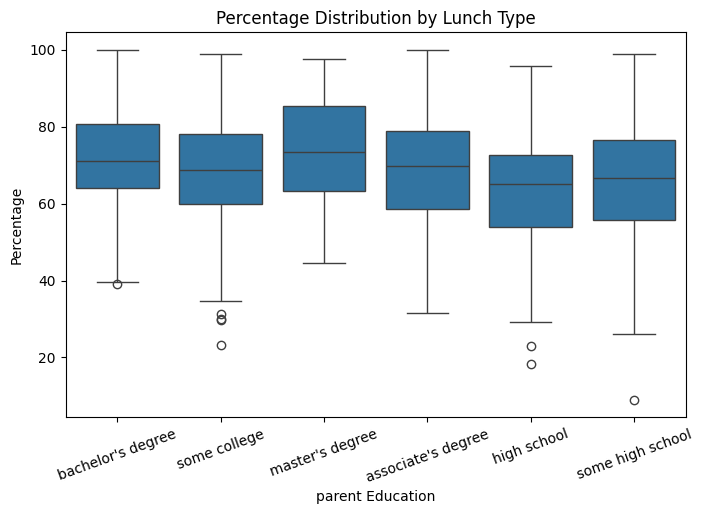

In [39]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='parental_level_of_education',
    y='percentage'
)

plt.title('Percentage Distribution by Lunch Type')
plt.xlabel('parent Education')
plt.ylabel('Percentage')
plt.xticks(rotation=20)
plt.show()

In [40]:
df.columns

Index(['gender', 'ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score', 'percentage', 'grade', 'performance'],
      dtype='object')

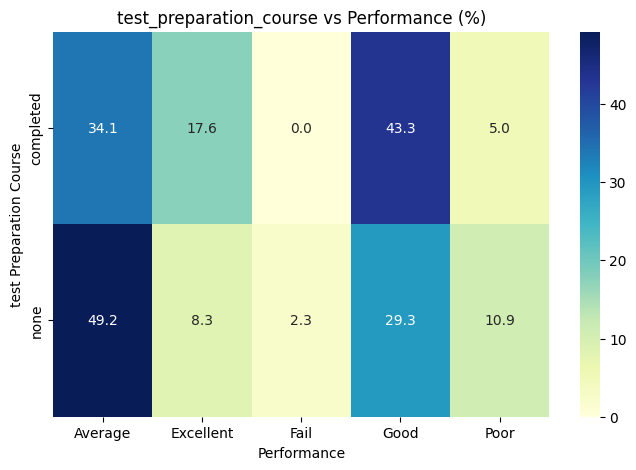

In [41]:
ct = pd.crosstab(
    df['test_preparation_course'],
    df['performance'],
    normalize='index'
) * 100

plt.figure(figsize=(8, 5))

sns.heatmap(
    ct,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('test_preparation_course vs Performance (%)')
plt.xlabel('Performance')
plt.ylabel('test Preparation Course')
plt.show()

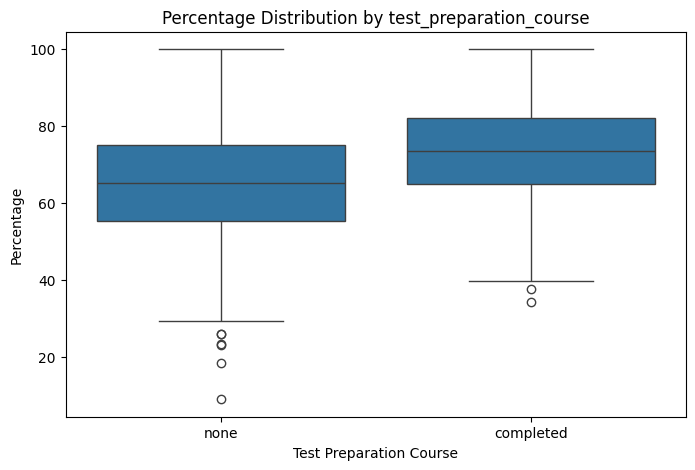

In [42]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='test_preparation_course',
    y='percentage'
)

plt.title('Percentage Distribution by test_preparation_course')
plt.xlabel('Test Preparation Course')
plt.ylabel('Percentage')
plt.show()

In [43]:
conditions = [
    df['math_score'] < 33,
    df['math_score'] < 50,
    df['math_score'] < 70,
    df['math_score'] < 85,
    df['math_score'] <= 100
]

categories = ['Fail', 'Poor', 'Average', 'Good', 'Excellent']
df['m_per'] = np.select(conditions, categories, default='Unknown')


conditions = [
    df['reading_score'] < 33,
    df['reading_score'] < 50,
    df['reading_score'] < 70,
    df['reading_score'] < 85,
    df['reading_score'] <= 100
]

df['r_per'] = np.select(conditions, categories, default='Unknown')


conditions = [
    df['writing_score'] < 33,
    df['writing_score'] < 50,
    df['writing_score'] < 70,
    df['writing_score'] < 85,
    df['writing_score'] <= 100
]

df['w_per'] = np.select(conditions, categories, default='Unknown')

In [44]:
import mysql.connector

try:
    conn = mysql.connector.connect(
        host="127.0.0.1",
        user='root',
        password="",
        database="project"
    )
    mycourser = conn.cursor()
    print("Connect to MySQL database")
except Exception as e:
    print('Error : ', e)

Error :  2003: Can't connect to MySQL server on '127.0.0.1:3306' (10061 No connection could be made because the target machine actively refused it)


In [ ]:
from sqlalchemy import create_engine

engine = create_engine(
    "mysql+pymysql://root:@127.0.0.1/project"  # last me hame database ka name dena haii
)

df.to_sql(
    "student",  # yaha pe hame table ka name dena haii
    con=engine,
    if_exists="replace",
    index=False
)

In [ ]:
df.columns

Index(['gender', 'ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score', 'percentage', 'grade', 'performance', 'm_per', 'r_per',
       'w_per'],
      dtype='object')